<a href="https://colab.research.google.com/github/ivorywang-1005/intro-to-urban-data/blob/main/Scale/S14_Grid_to_Map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **14 Scale**  Grid to Map

```
    Class       ARCH 6131 Urban Design Methods / Skills / Tools 1
                Tata Innovation Center
                Fall 2026
                Monday 4:00 PM to 6:30 PM

    Instructor  Ivory Wang
                tw295@cornell.edu
```


In this notebook, we'll keep building our geospatial toolkit with Colab, Python, and GeoPandas. This time, we'll move between two scales: the individual lot and the city.

Our example task is to find **underbuilt lots in Manhattan**: lots where buildings cover only a small share of the land and stand relatively low. We'll measure every lot, filter for the ones that fit our criteria, and then lay them out two ways: first side by side in a **grid**, so you can compare their shapes directly, and then back in their real locations on a **map**.

The process will look like this:

- Load tax lots (PLUTO) and clip them to Manhattan using the borough boundary
- Load building footprints and clip them with the same boundary
- Join buildings to lots and calculate each lot's **average building height** and **lot coverage**
- Filter for lots with low coverage and low height
- Arrange the filtered lots in a grid, then place them on a map
- Export the results for use in Rhino

Let's get started!

## Setup the notebook
Let's get started! First, let's set up our notebook by connecting it to Google Drive and importing dependencies. If you've opened this notebook from GitHub, you can save it as a copy in Google Drive. I recommend doing this first so you can save changes as you add them.

In [ ]:
# Connect to Google Drive
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Finally, set the path to the data directory
DATA_DIRECTORY = "/content/drive/MyDrive/ARCH 6131/Example Data"
!ls "{DATA_DIRECTORY}"

 06_Grasshopper_and_wiring_it_up.ipynb
'Borough Boundaries.geojson'
 brooklyn_city_vacant_lots.geojson
'Building Footprints'
'Building Footprints.zip'
 buildings_full.geojson
 buildings.geojson
 building.zip
 Bus_Lanes_-_Local_Streets_20231024.csv
'Cornell Example Data'
 example.3dm
 example.csv
 Forestry_Tree_Points_20231017.csv
 GML
 IMG_1605.HEIC
 IMG_3045.JPG
 IMG_4106.HEIC
 IMG_4108.HEIC
 lower_manhattan_buildings
 map.geojson
 nyc_buildings
 nyc_mappluto_23v2_shp
 NYC_Parks_Drinking_Fountains_20241028.csv
'Parks Properties_20241028.geojson'
 pluto.geojson
 trees
 trees.geojson


In [ ]:
!pip install rhino3dm --quiet

In [ ]:
# We just need a small set of external Python packages to start
import pandas as pd
import geopandas as gpd
from pathlib import Path
import rhino3dm

With our Notebook set up, we're good to go!

## Step 1 — Fetch data from open-source websites
A lot of great geospatial data for NYC — and other cities — is available through open-source data portals! You can browse a catalog of such data layers at https://opendata.cityofnewyork.us/data/. And feel free to search for others! They will typically offer data to be downloaded as GeoJSON, Shapefile (as SHP or ZIP), KMZ or other geospatial formats. Most if not all of which can be opened by GeoPandas!

We'll download and use three data sources in this note book — take a moment to review them. Then, download the files in the format of your choice and add to your Google Drive.
- [Borough boundaries](https://data.cityofnewyork.us/City-Government/Borough-Boundaries/tqmj-j8zm)
- [Primary Land Use Tax Lot Output data aka PLUTO](https://www.nyc.gov/site/planning/data-maps/open-data/dwn-pluto-mappluto.page)
- [Building footprints](https://data.cityofnewyork.us/Housing-Development/Building-Footprints/nqwf-w8eh)

For larger file formats, your choice of file format will impact how quickly you can load and access data, and you'll see that below.


### Borough boundaries
The boroughs file is small and can be easily read as a simple GeoJSON. There are only five boroughs, of course.

The file's original CRS is 'EPSG:4326'


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

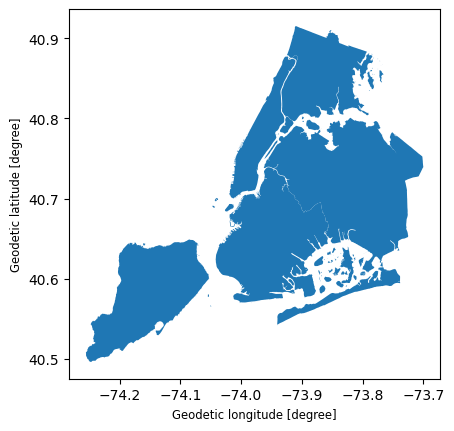

In [ ]:
# Load in a GeoJSON
boroughs_gdf = gpd.read_file(Path(DATA_DIRECTORY) / "Borough Boundaries.geojson")
print(f"The file's original CRS is '{boroughs_gdf.crs}'")

boroughs_gdf.plot()

In [ ]:
# Change the projection with .to_crs() to ESPG 2263
boroughs_gdf.to_crs(2263, inplace=True)
print(f"The file's adjusted CRS is '{boroughs_gdf.crs}' or '{boroughs_gdf.crs.name}'")

The file's adjusted CRS is 'EPSG:2263' or 'NAD83 / New York Long Island (ftUS)'


For simplicity, let's look at just one borough — Manhattan. We can use properties like `.loc()` to retrieve specific cells.

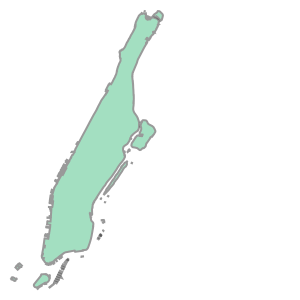

In [ ]:
# We can use .loc to find cells by index and name
# This gets the geometry from the fourth row
manhattan_geom = boroughs_gdf.loc[3, "geometry"]
manhattan_geom

### Tax lots

The PLUTO tax lots are large!How many tax lots do you think are in NYC? In the borough of Manhattan?

 The file itself is >100MB. Loading this into the Notebook can take several minutes. There are a few ways to speed this up:

- Read from a Shapefile folder, instead of a ZIP archive.
- Load in just one record using the `rows` argument.
- Filter the area you want to extract by another geometry using `mask`` or `bbox`

Loading in just one record is a great way to check a dataset's attribtues for a large Shapefile. But watch out! If you do this using the ZIP archive it will take much longer, as GeoPandas needs to expand and decompress the entire file first. Let's start by loading in one row first.

In [ ]:
# Load in exactly one row of the dataset — this is very fast!
one_lot_gdf = gpd.read_file(Path(DATA_DIRECTORY) / "nyc_mappluto_23v2_shp", rows=1)
one_lot_gdf

,Borough,Block,Lot,CD,BCT2020,BCTCB2020,CT2010,CB2010,SchoolDist,Council,...,FIRM07_FLA,PFIRM15_FL,Version,DCPEdited,Latitude,Longitude,Notes,Shape_Leng,Shape_Area,geometry
0,MN,1,201,101,1000100,10001001000,1,1000,02,0,...,None,1,23v2,None,40.698188,-74.041329,None,0.0,1.148539e+06,"POLYGON ((973648.066 193711.894, 973525.342 19..."


In [ ]:
# This one-row dataset has exactly the same CRS as the full dataset
print(
    f'The one-row dataset has CRS "{one_lot_gdf.crs}": and shape {one_lot_gdf.shape}'
)

The one-row dataset has CRS "EPSG:2263": and shape (1, 95)


We only want lots for the borough of Manhattan. We can load in just the relevant lots using the `mask` or `bbox` argument. Note that the CRS of the dataset was  "NAD83 / New York Long Island (ftUS)". Good that we've already converted a geometry of Manahttan to that coordinate reference system before!


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

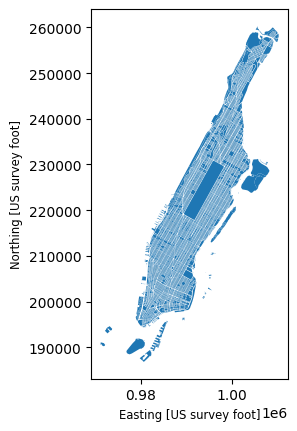

In [ ]:
lots_gdf = gpd.read_file(
    Path(DATA_DIRECTORY) / "nyc_mappluto_23v2_shp",
    mask=manhattan_geom,
    use_arrow=True,
)
lots_gdf.plot()

### Building footprints

Building footprints take even longer. Let's repeat the process by looking at one row first.

In [ ]:
# Load in exactly one row of the dataset — this is very fast!
one_building_gdf = gpd.read_file(Path(DATA_DIRECTORY) / "buildings_full.geojson", rows=1)
one_building_gdf

,:id,:version,:created_at,:updated_at,name,bin,doitt_id,shape_area,base_bbl,objectid,construction_year,feature_code,geom_source,ground_elevation,height_roof,last_edited_date,last_status_type,mappluto_bbl,shape_length,geometry
0,row-rafv~hmb6.y4j8,rv-7wmj~h7mn~bx3t,2025-05-27 20:52:58.168000+00:00,2025-05-27 20:52:58.168000+00:00,None,2019299,353927,217.17578125,2033800084,229537,1910,2100,Photogrammetric,197,33.49,2017-08-22 18:57:18+00:00,Constructed,2033800084,63.268290421653646,"MULTIPOLYGON (((-73.86996 40.90031, -73.86995 ..."


In [ ]:
# This one-row dataset has exactly the same CRS as the full dataset
print(f'The one-row dataset has CRS "{one_building_gdf.crs.name}"')

The one-row dataset has CRS "WGS 84"


This dataset is back in WGS84 — so we'll need to update that to match the lots gdf.


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

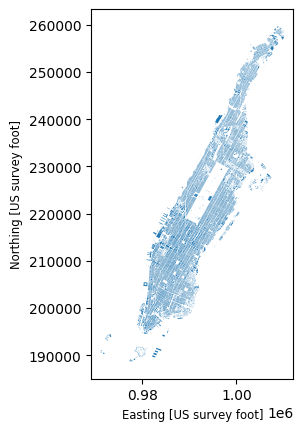

In [ ]:
# Loading the entire dataset takes ~30 seconds for me.
buildings_gdf = gpd.read_file(
    Path(DATA_DIRECTORY) / "buildings_full.geojson",
    mask=manhattan_geom_wgs84,
    use_arrow=True,
)
buildings_gdf = buildings_gdf.to_crs(2263)
buildings_gdf.plot()

## Review and project the data so its suitable for use
After loading the data it's always a good idea to review the size, shape, columns, CRS and other details. When doing this, you should also look at the supporting documentation and data dictionaries.

A nice way to look at quantiative values is `describe()`. This gives summary statistics for each columns

In [ ]:
# Summarize a dataset using describe
buildings_gdf.describe()

,:id,:version,:created_at,:updated_at,name,bin,doitt_id,shape_area,base_bbl,objectid,construction_year,feature_code,geom_source,ground_elevation,height_roof,last_edited_date,last_status_type,mappluto_bbl,shape_length,geometry
count,45188,45188,45188,45188,907,45188,45188,45188,45188,45188,44358,45188,45164,45129,45188,45188,45146,45188,45188,45188
unique,45188,45188,NaN,NaN,878,45188,45188,40419,40192,45188,235,10,3,261,17391,NaN,10,40141,45188,45188
top,row-m727.5zk5_5xpe,rv-6f6g-yfqp~ukt6,NaN,NaN,Kimball Block,1051480,794958,153.6640625,1000010010,11814,1910,2100,Photogrammetric,26,60,NaN,Constructed,1000010010,216.55744884999956,MULTIPOLYGON (((996898.1350275191 226702.87853...
freq,1,1,NaN,NaN,6,1,1,7,132,1,6393,44618,39624,1243,105,NaN,44845,132,1,1
mean,NaN,NaN,2026-04-26 08:12:46.328000+00:00,2026-04-26 08:12:46.328000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018-05-18 05:32:05.251000+00:00,NaN,NaN,NaN,NaN
min,NaN,NaN,2025-05-27 20:52:58.168000+00:00,2025-05-27 20:52:58.168000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2008-02-27 00:00:00+00:00,NaN,NaN,NaN,NaN
25%,NaN,NaN,2026-07-05 15:02:13.379000+00:00,2026-07-05 15:02:13.379000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-08-22 18:00:00+00:00,NaN,NaN,NaN,NaN
50%,NaN,NaN,2026-07-05 15:02:13.379000+00:00,2026-07-05 15:02:13.379000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-08-22 18:51:58+00:00,NaN,NaN,NaN,NaN
75%,NaN,NaN,2026-07-05 15:02:13.379000+00:00,2026-07-05 15:02:13.379000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-28 17:15:14+00:00,NaN,NaN,NaN,NaN
max,NaN,NaN,2026-10-25 08:21:06.997000+00:00,2026-10-25 08:21:06.997000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-23 20:23:30+00:00,NaN,NaN,NaN,NaN


In [ ]:
# Compare the CRS for all datasets
for df in (boroughs_gdf, lots_gdf, buildings_gdf):
    print(df.crs)

EPSG:2263
EPSG:2263
EPSG:2263


It looks like the buildings data set is in the WGS 84 CRS. We should covnert it to NAD83.

## Step 2: Filter and join the datasets

**Goal:** one row per lot (`BBL`) with **average building height** and **lot coverage**.

1. Spatially join buildings to lots (`gpd.sjoin(buildings_gdf, lots_gdf[['BBL','geometry']], predicate='intersects')`), so each building knows which lot it's on.
2. Compute each building's footprint area (`.area`).
3. Group by `BBL` and aggregate:
   - average height → `mean` of the height column
   - total footprint → `sum` of building area
4. Lot coverage = total footprint ÷ lot area.

Let's start by making sure each field has the correct value type!

In [ ]:
buildings_gdf['height_roof'] = pd.to_numeric(buildings_gdf['height_roof'])
buildings_gdf['shape_area'] = pd.to_numeric(buildings_gdf['shape_area'])
buildings_gdf[':created_at'] = pd.to_datetime(buildings_gdf[':created_at'])

buildings_gdf.describe(include='all')

,:id,:version,:created_at,:updated_at,name,bin,doitt_id,shape_area,base_bbl,objectid,construction_year,feature_code,geom_source,ground_elevation,height_roof,last_edited_date,last_status_type,mappluto_bbl,shape_length,geometry
count,45188,45188,45188,45188,907,45188,45188,45188.000000,45188,45188,44358,45188,45164,45129,45188.000000,45188,45146,45188,45188,45188
unique,45188,45188,NaN,NaN,878,45188,45188,NaN,40192,45188,235,10,3,261,NaN,NaN,10,40141,45188,45188
top,row-m727.5zk5_5xpe,rv-6f6g-yfqp~ukt6,NaN,NaN,Kimball Block,1051480,794958,NaN,1000010010,11814,1910,2100,Photogrammetric,26,NaN,NaN,Constructed,1000010010,216.55744884999956,MULTIPOLYGON (((996898.1350275191 226702.87853...
freq,1,1,NaN,NaN,6,1,1,NaN,132,1,6393,44618,39624,1243,NaN,NaN,44845,132,1,1
mean,NaN,NaN,2026-04-26 08:12:46.328000+00:00,2026-04-26 08:12:46.328000+00:00,NaN,NaN,NaN,754.936048,NaN,NaN,NaN,NaN,NaN,NaN,76.377457,2018-05-18 05:32:05.251000+00:00,NaN,NaN,NaN,NaN
min,NaN,NaN,2025-05-27 20:52:58.168000+00:00,2025-05-27 20:52:58.168000+00:00,NaN,NaN,NaN,8.144531,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,2008-02-27 00:00:00+00:00,NaN,NaN,NaN,NaN
25%,NaN,NaN,2026-07-05 15:02:13.379000+00:00,2026-07-05 15:02:13.379000+00:00,NaN,NaN,NaN,200.045898,NaN,NaN,NaN,NaN,NaN,NaN,45.700000,2017-08-22 18:00:00+00:00,NaN,NaN,NaN,NaN
50%,NaN,NaN,2026-07-05 15:02:13.379000+00:00,2026-07-05 15:02:13.379000+00:00,NaN,NaN,NaN,317.939453,NaN,NaN,NaN,NaN,NaN,NaN,58.220000,2017-08-22 18:51:58+00:00,NaN,NaN,NaN,NaN
75%,NaN,NaN,2026-07-05 15:02:13.379000+00:00,2026-07-05 15:02:13.379000+00:00,NaN,NaN,NaN,725.825195,NaN,NaN,NaN,NaN,NaN,NaN,71.996707,2020-01-28 17:15:14+00:00,NaN,NaN,NaN,NaN
max,NaN,NaN,2026-10-25 08:21:06.997000+00:00,2026-10-25 08:21:06.997000+00:00,NaN,NaN,NaN,190324.050781,NaN,NaN,NaN,NaN,NaN,NaN,1550.000000,2026-10-23 20:23:30+00:00,NaN,NaN,NaN,NaN


In [ ]:
lots_gdf=lots_gdf[['BBL', 'geometry', 'Shape_Area']]
lots_gdf['BBL'] = lots_gdf['BBL'].astype('int64')

lots_gdf.describe(include='all')

,BBL,geometry,Shape_Area
count,4.218100e+04,42181,4.218100e+04
unique,NaN,42181,NaN
top,NaN,"POLYGON ((973648.065694809 193711.8939294815, ...",NaN
freq,NaN,1,NaN
mean,1.013702e+09,NaN,1.099841e+04
std,5.306038e+07,NaN,2.046113e+05
min,1.000010e+09,NaN,7.103977e-01
25%,1.006980e+09,NaN,2.006960e+03
50%,1.012510e+09,NaN,2.659918e+03
75%,1.017680e+09,NaN,6.219908e+03


In [ ]:
buildings_gdf=buildings_gdf[['height_roof', 'geometry']]
buildings_gdf.head(1)

,height_roof,geometry
0,167.16,"MULTIPOLYGON (((996898.135 226702.879, 996882...."


Why not just use a spatial join? With `sjoin(..., predicate="intersects")`, a building counts as "on" a lot if it touches it **at all**. Lot lines and building footprints come from different datasets and rarely line up perfectly, so a building that sits on one lot often pokes a few inches into its neighbors. Each neighbor then gets that building's height, and our averages get messy.

Instead, we **overlap** the two layers with `gpd.overlay(buildings_gdf, lots_gdf, how="intersection")`. This cuts every building along the lot lines and gives us one piece for each building–lot pair, along with its **overlap area**. Now we can ask how much of this building actually sits on this lot.

1. Make sure both layers are in **EPSG:2263** (NY State Plane, units in feet), so `.area` comes out in square feet.
2. Overlay buildings and lots, then compute `overlap_area = .area` for each piece.
3. Keep only pairs with **more than 100 sq ft of overlap**. This drops the slivers caused by misaligned edges, so each building is only counted on the lot(s) it really stands on.

⚠️ The 100 sq ft cutoff also removes genuinely small buildings, such as sheds and garages, that cover less than 100 sq ft. For this exercise that's fine, because we care about the main building on each lot, but keep it in mind. Try 1,000 or 5,000 and see how the results change!

In [ ]:
overlapping = gpd.overlay(lots_gdf, buildings_gdf, how='intersection')
overlapping['overlapping_sqft'] = overlapping.area
overlapping.head(5)

,BBL,Shape_Area,height_roof,geometry,overlapping_sqft
0,1000010201,1.148539e+06,34.0,"POLYGON ((972742.977 193212.247, 972674.847 19...",5381.017578
1,1000010201,1.148539e+06,19.0,"POLYGON ((973237.325 194388.502, 973223.398 19...",2250.659979
2,1000010201,1.148539e+06,12.0,"POLYGON ((973230.746 194534.405, 973175.517 19...",1205.962755
3,1000010201,1.148539e+06,87.0,"POLYGON ((972864.103 193688.919, 972873.66 193...",11193.142137
4,1000010201,1.148539e+06,87.0,"POLYGON ((972847.903 193673.319, 972840.74 193...",30741.930090


In [ ]:
building_lot_pair = overlapping[overlapping['overlapping_sqft']>100]

⚠️ `groupby` returns a plain **DataFrame**, so the geometry is gone. Merge the lot geometry back on `BBL` and rebuild a GeoDataFrame:
`gpd.GeoDataFrame(df, geometry="geometry", crs=lots_gdf.crs)`.

Use `type(x)` whenever you're unsure what kind of object you have.

In [ ]:
stats=building_lot_pair.groupby('BBL')
stats.size().sort_values(ascending=False)

,0
BBL,
1000010010,129
1011110001,62
1013730001,57
1018190010,52
1018190015,52
...,...
1022500058,1
1022500054,1
1022500050,1


In [ ]:
lots_stats = stats.agg(
    num_buildings=("height_roof", "count"),
    avg_bldg_height=("height_roof", "mean"),
    covered_area = ('overlapping_sqft', "sum")
)

In [ ]:
lots_stats = lots_stats.merge(lots_gdf[['BBL', 'Shape_Area']],
                              on="BBL",
                              how="left")

In [ ]:
lots_stats['coverage_percentage'] = lots_stats['covered_area']/lots_stats['Shape_Area']

## Step 3 — Filter for underbuilt lots

**Goal:** keep lots with **low coverage** and **low building height**, i.e. lots that use little of their potential.

1. Look at the distributions first: `lots_stats["coverage"].describe()`, `.hist()`.
2. Pick thresholds, e.g. coverage < `[0.x]` and height < `[x ft]`.
3. Save the result as `lots_stats_filtered`.

💡 Try a few thresholds and watch how the count changes. Write down why you chose yours.

In [ ]:
lots_stats_filtered =lots_stats[(lots_stats['coverage_percentage'] <.60) & (lots_stats['Shape_Area']> 300000)& (lots_stats['Shape_Area'] < 1000000)]
lots_stats_filtered.count()

,0
BBL,71
num_buildings,71
avg_bldg_height,71
covered_area,71
Shape_Area,71
coverage_percentage,71


In [ ]:
# Bring back the geometry
lots_stats_filtered = lots_stats_filtered.merge(lots_gdf[['BBL', 'geometry']],
                              on="BBL",
                              how="left")

In [ ]:
# Build a geodataframe
lots_stats_filtered = gpd.GeoDataFrame(
    lots_stats_filtered, geometry="geometry", crs=lots_gdf.crs
)
# Drop unnecessary fields
lots_stats_filtered = lots_stats_filtered[["BBL", "num_buildings", "avg_bldg_height", "coverage_percentage", "geometry"]]
lots_stats_filtered.head(5)

,BBL,num_buildings,avg_bldg_height,coverage_percentage,geometry
0,1000010101,10,27.975726,0.223769,"MULTIPOLYGON (((972428.829 190679.175, 972443...."
1,1000030001,9,19.415806,0.046307,"MULTIPOLYGON (((980089.365 194658.743, 980083...."
2,1000580001,7,545.574716,0.357239,"POLYGON ((980801.279 199022.76, 980936.63 1989..."
3,1000940001,11,154.430192,0.406257,"POLYGON ((982850.846 197563.936, 982907.63 197..."
4,1001110100,13,139.839379,0.156682,"POLYGON ((985101.08 198425.228, 984948.206 198..."


## Step 4  — Lay out the lots as a grid, then as a map

**Goal:** draw the filtered lots twice: first side by side in a grid (to compare shapes), then in their real locations.

1. **Grid:** move each lot's geometry so it sits in its own cell (e.g. `[n]` columns, fixed spacing), ignoring real-world position. Export with `rhino3dm` to a `.3dm` file.
2. **Map:** draw the same lots at their true coordinates. Optionally extrude by average height.
3. Save both outputs to your Drive folder.

✅ **Check:** the number of shapes in the grid equals `len(lots_stats_filtered)`.

In [ ]:
from shapely.affinity import translate, scale

COLS = 10

# order by North to South to relate to the map
# lots_stats_filtered = lots_stats_filtered.sort_values("coverage_percentage", ascending=False).reset_index(drop=True)
lots_stats_filtered['centroid'] = lots_stats_filtered.geometry.centroid
lots_stats_filtered["cy"] = lots_stats_filtered.geometry.centroid.y
lots_stats_filtered = lots_stats_filtered.sort_values("cy", ascending=False)  # north first
lots_stats_filtered.head(5)

,BBL,num_buildings,avg_bldg_height,coverage_percentage,geometry,centroid,cy
68,2057160725,2,95.110000,0.098523,"POLYGON ((1009036.158 259866.332, 1009227.212 ...",POINT (1008023.686 259136.907),259136.907346
65,1022150080,4,164.410000,0.186007,"POLYGON ((1009090.859 259533.68, 1008727.424 2...",POINT (1008326.777 258917.056),258917.056452
66,1022150116,7,125.625174,0.125910,"POLYGON ((1010025.373 258363.258, 1010026.968 ...",POINT (1009741.106 258029.103),258029.103458
67,1022160001,8,119.176250,0.139626,"POLYGON ((1006125.914 253353.995, 1005549.25 2...",POINT (1005638.078 253025.984),253025.983729
64,1021600018,17,17.035190,0.271059,"POLYGON ((1004685.349 250754.374, 1004361.644 ...",POINT (1004722.295 251370.133),251370.133006


,BBL,num_buildings,avg_bldg_height,coverage_percentage,geometry,centroid,cy
68,2057160725,2,95.110000,0.098523,"POLYGON ((3270.561 -1715.691, 3461.615 -1920.7...",POINT (2258.089 -2445.115),259136.907346
65,1022150080,4,164.410000,0.186007,"POLYGON ((7749.259 -1763.414, 7385.823 -2104.4...",POINT (6985.177 -2380.037),258917.056452
66,1022150116,7,125.625174,0.125910,"POLYGON ((12117.693 -2069.986, 12119.287 -2180...",POINT (11833.425 -2404.14),258029.103458
67,1022160001,8,119.176250,0.139626,"POLYGON ((16944.295 -1937.249, 16367.631 -2974...",POINT (16456.459 -2265.26),253025.983729
64,1021600018,17,17.035190,0.271059,"POLYGON ((21145.106 -2930.482, 20821.401 -2752...",POINT (21182.052 -2314.723),251370.133006


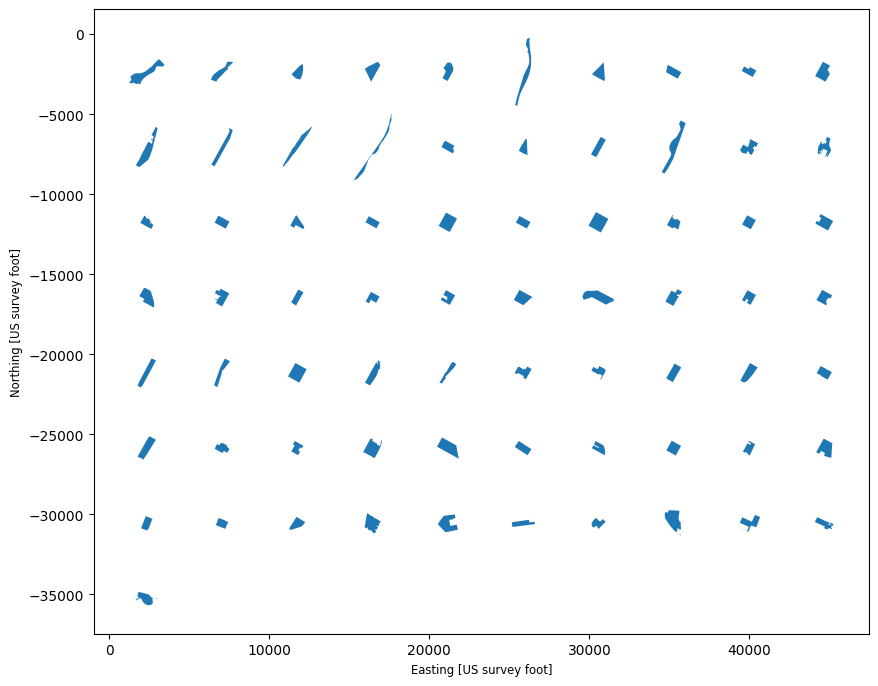

In [ ]:
# Cell size: the largest lot's bounding box + 10% padding
b = lots_stats_filtered.bounds
cell = max((b.maxx - b.minx).max(), (b.maxy - b.miny).max()) * 1.1

new_geoms = []
for i, geom in enumerate(lots_stats_filtered.geometry):
    row, col = divmod(i, COLS)                 # i=0 → (0,0), i=10 → (1,0) ...
    minx, miny, maxx, maxy = geom.bounds

    # move the lot's bounding-box center to the cell's center
    dx = (col * cell + cell / 2) - (minx + maxx) / 2
    dy = -(row * cell + cell / 2) - (miny + maxy) / 2   # rows go downward
    new_geoms.append(translate(geom, xoff=dx, yoff=dy))

lots_grid = lots_stats_filtered.copy()
lots_grid["geometry"] = new_geoms
lots_grid["centroid"] = lots_grid["geometry"].centroid
lots_grid.plot(figsize=(10, 10))   # check before writing to Rhino
lots_grid.head(5)

In [ ]:
lots_map = lots_gdf.copy()
lots_map['centroid'] = lots_map['geometry'].centroid

In [ ]:
model = rhino3dm.File3dm()
model.Settings.ModelUnitSystem = rhino3dm.UnitSystem.Feet  # EPSG:2263 is in feet

def add_layer(model, name, color):
    layer = rhino3dm.Layer()
    layer.Name = name
    layer.Color = (*color, 255)  # RGBA
    return model.Layers.Add(layer)  # returns the layer index

layers = {
    "grid_geometry": add_layer(model, "Grid Geometry", (0, 0, 0)),
    "grid_anchor":   add_layer(model, "Grid Anchor",   (255, 0, 0)),
    "map_geometry":  add_layer(model, "Map Geometry",  (0, 0, 255)),
    "map_anchor":    add_layer(model, "Map Anchor",    (255, 128, 0)),
}

def attrs_for(layer_key):
    a = rhino3dm.ObjectAttributes()
    a.LayerIndex = layers[layer_key]
    return a

In [ ]:
from shapely.geometry import MultiPolygon

def to_rhino_curves(geom):
    """Shapely (Multi)Polygon -> list of closed rhino3dm curves."""
    polys = geom.geoms if isinstance(geom, MultiPolygon) else [geom]
    curves = []
    for poly in polys:
        pl = rhino3dm.Polyline()
        for x, y in poly.exterior.coords:
            pl.Add(x, y, 0)
        curves.append(pl.ToPolylineCurve())
    return curves

def to_rhino_point(pt):
    return rhino3dm.Point3d(pt.x, pt.y, 0)

In [ ]:
# helper function to add attribute
def attrs_for(layer_key, name=None):
    a = rhino3dm.ObjectAttributes()
    a.LayerIndex = layers[layer_key]
    if name is not None:
        a.Name = str(name)
    return a

# Add geometries + BBL together
for bbl, geom in zip(lots_grid['BBL'], lots_grid['geometry']):
    for crv in to_rhino_curves(geom):
        model.Objects.AddCurve(crv, attrs_for("grid_geometry", bbl))
for bbl, pt in zip(lots_grid['BBL'], lots_grid['centroid']):
    model.Objects.AddPoint(to_rhino_point(pt), attrs_for("grid_anchor", bbl))
for bbl, geom in zip(lots_map['BBL'], lots_map['geometry']):
    for crv in to_rhino_curves(geom):
        model.Objects.AddCurve(crv, attrs_for("map_geometry", bbl))
for bbl, pt in zip(lots_map['BBL'], lots_map['centroid']):
    model.Objects.AddPoint(to_rhino_point(pt), attrs_for("map_anchor", bbl))

model.Write("grid_to_map.3dm", 7)

True

In [ ]:
# export data csv
lots_grid.drop(columns=["geometry", "cy"]).to_csv("lots_grid.csv", index=False)